# Data Preprocessing and Feature Engineering

## Project: Credit Risk Analytics — Predicting Credit Card Default

### 3.1 Introduction

Data preprocessing prepares the dataset for machine learning by improving data consistency, handling categorical variables and preparing numerical features.

This phase focuses on validating feature values, investigating unusual observations, selecting appropriate transformations and preparing the training and testing datasets.

### Objectives

1. Investigate undocumented and unusual categorical values.
2. Examine negative billing amounts and extreme observations.
3. Prepare categorical and numerical features.
4. Evaluate appropriate feature transformations.
5. Separate predictor variables from the target variable.
6. Split the dataset into training and testing sets.
7. Build preprocessing pipelines while preventing data leakage.

All preprocessing decisions will be based on the dataset's characteristics and the requirements of the selected machine learning models.

### 3.2 Import Libraries and Load Dataset

The required libraries will be imported, and the original dataset will be loaded again.

The dataset will be structurally corrected by promoting its first row to column headers and converting all variables to numeric data types.

A separate working copy will be created so that the original dataset remains unchanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Define dataset path
DATA_PATH = Path("../data/default of credit card clients.xls")

# Load original dataset
df_raw = pd.read_excel(DATA_PATH)

# Create a working copy
df = df_raw.copy()

# Correct column headers
df.columns = df.iloc[0].astype(str).str.strip()

# Remove the original header row
df = df.iloc[1:].reset_index(drop=True)

# Convert all columns to numeric data types
df = df.apply(pd.to_numeric)

# Verify the prepared dataset
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes.value_counts())

print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (30000, 25)

Data Types:
int64    25
Name: count, dtype: int64

First Five Records:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 3.3 Categorical Feature Validation

The dataset contains three demographic categorical variables:

- SEX
- EDUCATION
- MARRIAGE

Although these variables are stored as integers, their values represent categories rather than continuous numerical measurements.

This section will examine their unique values and frequency distributions to identify undocumented, unknown or unusual categories.

The original category codes will be preserved during this investigation. No categories will be merged or removed without justification.

In [2]:
# Identify categorical variables
categorical_columns = ["SEX", "EDUCATION", "MARRIAGE"]

# Display unique values and frequency distributions
for column in categorical_columns:
    print(f"\nColumn: {column}")
    print("Unique Values:", sorted(df[column].unique()))
    print("\nValue Counts:")
    print(df[column].value_counts().sort_index())
    print("-" * 50)


Column: SEX
Unique Values: [np.int64(1), np.int64(2)]

Value Counts:
SEX
1    11888
2    18112
Name: count, dtype: int64
--------------------------------------------------

Column: EDUCATION
Unique Values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Value Counts:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64
--------------------------------------------------

Column: MARRIAGE
Unique Values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Value Counts:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64
--------------------------------------------------


### 3.4 Summary of Categorical Distributions

A consolidated frequency table will be generated to make the category distributions easier to inspect.

Special attention will be given to undocumented and unknown category codes in EDUCATION and MARRIAGE.

These values will be retained until an appropriate preprocessing strategy is established.

In [3]:
# Generate a consolidated frequency distribution
categorical_summary = pd.concat(
    {
        column: df[column].value_counts().sort_index()
        for column in categorical_columns
    },
    axis=1
).fillna(0).astype(int)

# Display all categories without truncation
display(categorical_summary)

,SEX,EDUCATION,MARRIAGE
1,11888,10585,13659
2,18112,14030,15964
0,0,14,54
3,0,4917,323
4,0,123,0
5,0,280,0
6,0,51,0


### 3.5 Handling Undocumented and Unknown Categories

The categorical analysis identified the following unusual values:

- EDUCATION: Code 0 is undocumented, while codes 5 and 6 represent unknown categories.
- MARRIAGE: Code 0 is undocumented.
- SEX: Contains only the expected categories 1 and 2.

These observations will not be removed.

For preprocessing, undocumented and unknown values will be grouped into an explicit "Unknown/Other" category. This prevents unnecessary data loss while ensuring that undocumented codes are not interpreted as meaningful numerical values.

The original dataset will remain unchanged, and category consolidation will be performed on the modeling dataset.

In [4]:
# Create a separate dataset for preprocessing
df_processed = df.copy()

# Group undocumented and unknown education categories
df_processed["EDUCATION"] = df_processed["EDUCATION"].replace({
    0: 4,
    5: 4,
    6: 4
})

# Group undocumented marriage category with Others
df_processed["MARRIAGE"] = df_processed["MARRIAGE"].replace({
    0: 3
})

# Verify updated category distributions
for column in categorical_columns:
    print(f"\n{column} Distribution:")
    print(df_processed[column].value_counts().sort_index())


SEX Distribution:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION Distribution:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

MARRIAGE Distribution:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


### 3.6 Investigation of Negative Billing Amounts

The initial data understanding phase identified negative values in the six billing amount variables.

These observations require investigation before deciding whether any transformation or correction is necessary.

The analysis will examine:

1. The number and percentage of negative billing values in each column.
2. The minimum and maximum values.
3. The distribution of negative billing amounts.
4. Whether negative values occur alongside different target classes.

Negative billing amounts will not be removed or replaced without supporting evidence.

In [5]:
# Identify billing amount columns
billing_columns = [f"BILL_AMT{i}" for i in range(1, 7)]

# Calculate negative value statistics
negative_billing_summary = pd.DataFrame({
    "Negative Count": (df_processed[billing_columns] < 0).sum(),
    "Negative Percentage": (
        (df_processed[billing_columns] < 0).mean() * 100
    ).round(2),
    "Minimum Value": df_processed[billing_columns].min(),
    "Maximum Value": df_processed[billing_columns].max()
})

display(negative_billing_summary)

,Negative Count,Negative Percentage,Minimum Value,Maximum Value
0,,,,
BILL_AMT1,590,1.97,-165580,964511
BILL_AMT2,669,2.23,-69777,983931
BILL_AMT3,655,2.18,-157264,1664089
BILL_AMT4,675,2.25,-170000,891586
BILL_AMT5,655,2.18,-81334,927171
BILL_AMT6,688,2.29,-339603,961664


In [6]:
# Compare negative billing values across target classes
negative_billing_by_target = df_processed.groupby(
    "default payment next month"
)[billing_columns].agg(
    lambda values: (values < 0).sum()
)

display(negative_billing_by_target)

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
default payment next month,,,,,,
0,481,542,526,557,525,555
1,109,127,129,118,130,133


### 3.7 Findings from Negative Billing Amount Analysis

The investigation identified negative values across all six billing amount variables.

Key observations:

- Negative values account for approximately 1.97%–2.29% of observations in each billing column.
- Negative billing amounts occur in both default and non-default classes.
- BILL_AMT6 contains the highest number of negative observations (688).
- The minimum observed billing amount is -339,603 in BILL_AMT6.

### Preprocessing Decision

Negative billing amounts will be retained in the dataset.

They may represent credit balances, adjustments or other legitimate account-level conditions. The available analysis does not establish that these values are data errors.

Any future feature transformation must therefore support negative values.

### 3.8 Investigation of Extreme Numerical Values

The exploratory analysis identified highly skewed distributions and extreme observations in billing and payment amount variables.

Before selecting a transformation strategy, the numerical features will be examined using descriptive statistics and the Interquartile Range (IQR) method.

The IQR method will be used to identify potential outliers, not automatically classify observations as errors.

No records will be deleted solely because they fall outside the IQR boundaries.

In [7]:
# Identify numerical amount columns
amount_columns = (
    billing_columns +
    [f"PAY_AMT{i}" for i in range(1, 7)]
)

# Calculate IQR-based outlier statistics
outlier_summary = []

for column in amount_columns:
    q1 = df_processed[column].quantile(0.25)
    q3 = df_processed[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df_processed[column] < lower_bound) |
        (df_processed[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": round(
            outlier_count / len(df_processed) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary).set_index("Feature")

display(outlier_summary)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
Feature,,,,,,,
BILL_AMT1,3558.75,67091.00,63532.25,-91739.625,162389.375,2400,8.00
BILL_AMT2,2984.75,64006.25,61021.50,-88547.500,155538.500,2395,7.98
BILL_AMT3,2666.25,60164.75,57498.50,-83581.500,146412.500,2469,8.23
BILL_AMT4,2326.75,54506.00,52179.25,-75942.125,132774.875,2622,8.74
BILL_AMT5,1763.00,50190.50,48427.50,-70878.250,122831.750,2725,9.08
BILL_AMT6,1256.00,49198.25,47942.25,-70657.375,121111.625,2693,8.98
PAY_AMT1,1000.00,5006.00,4006.00,-5009.000,11015.000,2745,9.15
PAY_AMT2,833.00,5000.00,4167.00,-5417.500,11250.500,2714,9.05
PAY_AMT3,390.00,4505.00,4115.00,-5782.500,10677.500,2598,8.66


### 3.9 Numerical Feature Skewness Analysis

Billing and payment variables contain potential extreme values. These observations may influence the distributions and the performance of certain machine learning algorithms.

Skewness will be calculated to measure the asymmetry of each numerical feature.

Interpretation:

- Skewness near 0: Approximately symmetric distribution.
- Positive skewness: Longer right tail.
- Negative skewness: Longer left tail.
- Absolute skewness above 1: Generally indicates substantial asymmetry.

The results will help determine whether transformations are appropriate for numerical features.

In [8]:
# Calculate skewness for billing and payment variables
skewness_summary = pd.DataFrame({
    "Skewness": df_processed[amount_columns].skew(),
    "Mean": df_processed[amount_columns].mean(),
    "Median": df_processed[amount_columns].median()
})

# Classify the distribution based on skewness
skewness_summary["Distribution"] = np.where(
    skewness_summary["Skewness"] > 1,
    "Highly Right-Skewed",
    np.where(
        skewness_summary["Skewness"] < -1,
        "Highly Left-Skewed",
        "Moderately Skewed or Approximately Symmetric"
    )
)

display(skewness_summary.round(2))

,Skewness,Mean,Median,Distribution
0,,,,
BILL_AMT1,2.66,51223.33,22381.5,Highly Right-Skewed
BILL_AMT2,2.71,49179.08,21200.0,Highly Right-Skewed
BILL_AMT3,3.09,47013.15,20088.5,Highly Right-Skewed
BILL_AMT4,2.82,43262.95,19052.0,Highly Right-Skewed
BILL_AMT5,2.88,40311.40,18104.5,Highly Right-Skewed
BILL_AMT6,2.85,38871.76,17071.0,Highly Right-Skewed
PAY_AMT1,14.67,5663.58,2100.0,Highly Right-Skewed
PAY_AMT2,30.45,5921.16,2009.0,Highly Right-Skewed
PAY_AMT3,17.22,5225.68,1800.0,Highly Right-Skewed


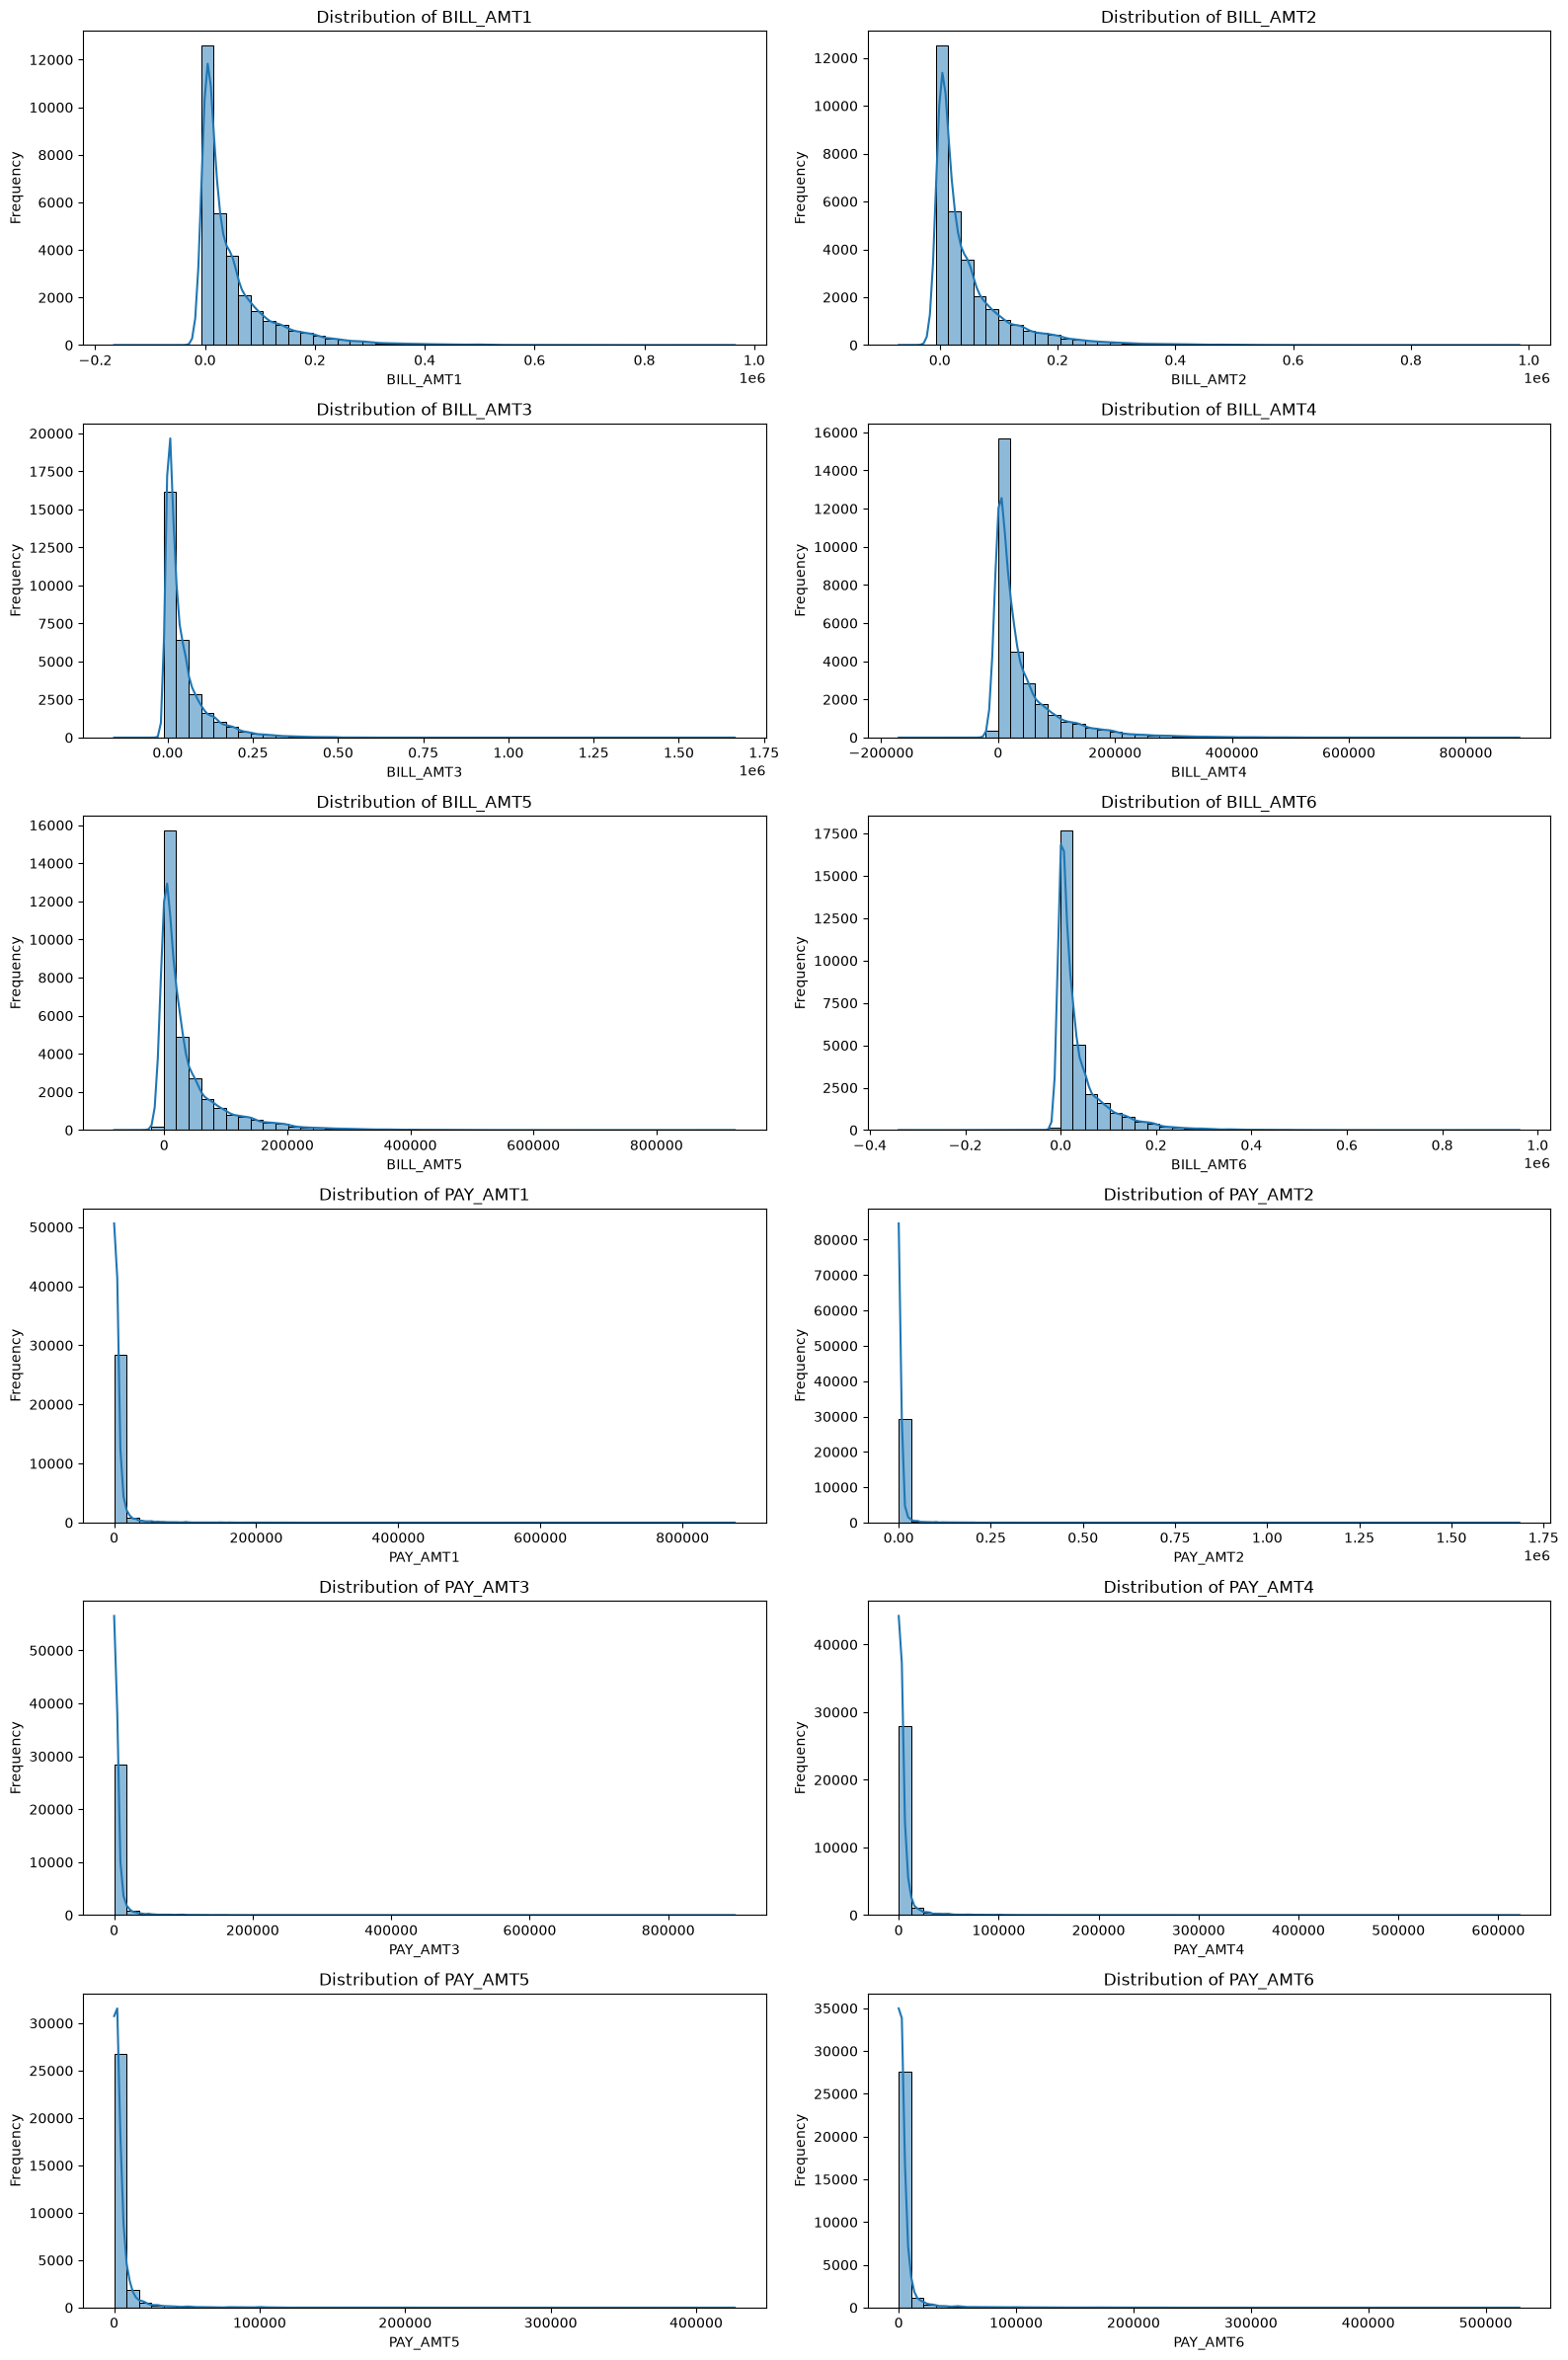

In [9]:
# Plot distributions of billing and payment variables
fig, axes = plt.subplots(6, 2, figsize=(16, 24))

for index, column in enumerate(amount_columns):
    row, col = divmod(index, 2)

    sns.histplot(
        data=df_processed,
        x=column,
        bins=50,
        kde=True,
        ax=axes[row, col]
    )

    axes[row, col].set_title(f"Distribution of {column}")
    axes[row, col].set_xlabel(column)
    axes[row, col].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 3.10 Feature Classification

The dataset contains demographic, financial and repayment-history variables.

The following feature groups will be used:

**1. Nominal categorical features**
- SEX
- EDUCATION
- MARRIAGE

**2. Repayment status features**
- PAY_0
- PAY_2
- PAY_3
- PAY_4
- PAY_5
- PAY_6

These variables contain discrete repayment status codes. They will initially be treated as categorical features to avoid assuming equal numerical distances between their codes.

**3. Numerical financial features**
- LIMIT_BAL
- BILL_AMT1 to BILL_AMT6
- PAY_AMT1 to PAY_AMT6

**4. Numerical demographic feature**
- AGE

The ID column will be excluded because it is an identifier rather than a meaningful predictive feature.

The target variable is `default payment next month`.

In [10]:
# Define nominal categorical features
nominal_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

# Define repayment status features
repayment_features = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

# Define numerical financial features
financial_features = [
    "LIMIT_BAL",
    *billing_columns,
    *[f"PAY_AMT{i}" for i in range(1, 7)]
]

# Define numerical demographic features
demographic_features = ["AGE"]

# Combine all predictor features
feature_columns = (
    nominal_features
    + repayment_features
    + financial_features
    + demographic_features
)

# Define target variable
target_column = "default payment next month"

# Separate features and target
X = df_processed[feature_columns].copy()
y = df_processed[target_column].copy()

# Verify feature selection
print("Number of Features:", len(feature_columns))
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts().sort_index())

Number of Features: 23
Feature Matrix Shape: (30000, 23)
Target Shape: (30000,)

Target Distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64


### 3.11 Splitting the Dataset

The dataset will be divided into training and testing subsets.

An 80:20 split will be used:

- Training set: 80% (24,000 observations)
- Testing set: 20% (6,000 observations)

Stratified sampling will preserve the original target-class proportions in both subsets.

A fixed random state of 42 will ensure reproducibility.

The test dataset will remain separate during model training and preprocessing.

In [11]:
from sklearn.model_selection import train_test_split

# Split the dataset while preserving target proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training Features: (24000, 23)
Testing Features: (6000, 23)

Training Target Distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Testing Target Distribution:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


### 3.12 Building the Preprocessing Pipeline

A ColumnTransformer will apply different preprocessing operations to different feature groups.

The following transformations will be used:

1. Nominal categorical features: One-hot encoding.
2. Repayment status features: One-hot encoding.
3. Numerical demographic and credit-limit features: Standard scaling.
4. Billing and payment amount features: Yeo-Johnson power transformation followed by standard scaling.

OneHotEncoder will use handle_unknown="ignore" to handle categories that may appear in testing data but were not encountered during training.

The preprocessing pipeline will be fitted exclusively on the training dataset. The fitted transformations will then be applied to the testing dataset.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PowerTransformer
)
from sklearn.pipeline import Pipeline

# Combine nominal and repayment status features
categorical_features = nominal_features + repayment_features

# Pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Pipeline for numerical demographic and credit-limit features
standard_numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Pipeline for skewed billing and payment features
amount_pipeline = Pipeline(steps=[
    ("power_transform", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

# Combine all preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, categorical_features),
        ("standard_numeric", standard_numeric_pipeline,
         demographic_features + ["LIMIT_BAL"]),
        ("amounts", amount_pipeline, amount_columns)
    ],
    remainder="drop"
)

# Fit transformations on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted transformations to testing data
X_test_processed = preprocessor.transform(X_test)

# Verify transformed datasets
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

print("\nTraining Data Type:", type(X_train_processed))
print("Testing Data Type:", type(X_test_processed))

print("\nMissing Values in Processed Training Data:",
      np.isnan(X_train_processed.data if hasattr(
          X_train_processed, "data"
      ) else X_train_processed).sum())

Original Training Shape: (24000, 23)
Processed Training Shape: (24000, 87)

Original Testing Shape: (6000, 23)
Processed Testing Shape: (6000, 87)

Training Data Type: <class 'scipy.sparse._csr.csr_matrix'>
Testing Data Type: <class 'scipy.sparse._csr.csr_matrix'>

Missing Values in Processed Training Data: 0


### 3.13 Validation of Preprocessed Data

The transformed datasets will be checked for numerical validity and structural consistency.

The validation will confirm:

1. Both datasets contain the same number of transformed features.
2. No NaN or infinite values are present.
3. The preprocessing pipeline generates meaningful feature names.
4. The transformed feature matrix is suitable for subsequent machine learning workflows.

The validation will help ensure that preprocessing has not introduced numerical errors.

In [13]:
# Retrieve generated feature names
transformed_feature_names = preprocessor.get_feature_names_out()

# Validate feature dimensions
assert X_train_processed.shape[1] == len(transformed_feature_names)
assert X_test_processed.shape[1] == len(transformed_feature_names)

# Validate numerical values in sparse matrices
assert np.isfinite(X_train_processed.data).all()
assert np.isfinite(X_test_processed.data).all()

# Display validation results
print("Training and Testing Feature Count:",
      len(transformed_feature_names))

print("\nAll transformed training values are finite:",
      np.isfinite(X_train_processed.data).all())

print("All transformed testing values are finite:",
      np.isfinite(X_test_processed.data).all())

print("\nFirst 20 Transformed Feature Names:")
for feature in transformed_feature_names[:20]:
    print(feature)

Training and Testing Feature Count: 87

All transformed training values are finite: True
All transformed testing values are finite: True

First 20 Transformed Feature Names:
categorical__SEX_1
categorical__SEX_2
categorical__EDUCATION_1
categorical__EDUCATION_2
categorical__EDUCATION_3
categorical__EDUCATION_4
categorical__MARRIAGE_1
categorical__MARRIAGE_2
categorical__MARRIAGE_3
categorical__PAY_0_-2
categorical__PAY_0_-1
categorical__PAY_0_0
categorical__PAY_0_1
categorical__PAY_0_2
categorical__PAY_0_3
categorical__PAY_0_4
categorical__PAY_0_5
categorical__PAY_0_6
categorical__PAY_0_7
categorical__PAY_0_8


### 3.14 Data Preprocessing — Summary and Findings

The data preprocessing phase has been completed successfully.

#### 1. Categorical Data Handling
- SEX contains two valid categories.
- EDUCATION codes 0, 4, 5 and 6 were grouped into category 4.
- MARRIAGE codes 0 and 3 were grouped into category 3.
- Nominal categorical and repayment status variables were one-hot encoded.

#### 2. Negative Values and Potential Outliers
- Negative billing amounts were retained.
- IQR analysis identified potential outliers in billing and payment variables.
- No observations were removed or capped based solely on statistical outlier boundaries.

#### 3. Numerical Transformations
- StandardScaler was applied to AGE and LIMIT_BAL.
- Yeo-Johnson transformation followed by StandardScaler was applied to billing and payment variables.

#### 4. Feature Selection
- ID was excluded from the predictor variables.
- The target variable was separated from the feature matrix.
- A total of 23 original predictor features were selected.

#### 5. Training and Testing Split
- Training observations: 24,000 (80%).
- Testing observations: 6,000 (20%).
- Stratified sampling preserved the target-class distribution.

#### 6. Final Preprocessed Dataset
- Original features: 23.
- Transformed features: 87.
- Training matrix: 24,000 × 87.
- Testing matrix: 6,000 × 87.
- No missing or infinite values were detected.

#### Conclusion

The dataset is now prepared for machine learning experimentation.

The preprocessing pipeline ensures consistent transformations between training and testing data while preventing data leakage from fitting preprocessing operations on the test set.

The fitted preprocessing object will be reused within the machine learning pipelines developed in the next phase.